# 02 · Feature engineering (without data leakage)

Every feature uses only information available at the moment of purchase. The history features (seller and route) are the trickiest, because it is easy to let information from the future slip in without noticing.

The logic lives in `src/features.py`. In this notebook I build the features, check that there is no leakage and look at how much signal each one carries.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from features import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, build_features, load_model_base
from plot_style import BLUE, INK_2, ORANGE, apply_style

apply_style()
FIG_DIR = "../reports/figures"

# Start of the test period. The smoothing priors are computed only from
# what was known before this date.
TEST_START = pd.Timestamp("2018-04-01")

df = load_model_base("../data/processed/model_base.csv")
X = build_features(df, cutoff=TEST_START)
print(f"{len(X):,} orders · {len(FEATURES)} features "
      f"({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)")

97,300 orders · 26 features (22 numeric, 4 categorical)


## 1. When does an order's outcome become known?

This is the key piece for avoiding leakage. A seller's history cannot include orders whose outcome was not yet known at the moment of purchase.

| Outcome | Known when... |
|---|---|
| On time | it is delivered (`delivered_ts`) |
| Late or not delivered | the promised day ends (00:00 on the day after `estimated_date`) |

A late order is "known" to be late once the promise expires, even if it arrives weeks later.

In [2]:
X[["order_id", "purchase_ts", "estimated_date", "delivered_ts", "is_late", "outcome_known_ts"]].sample(5, random_state=1)

,order_id,purchase_ts,estimated_date,delivered_ts,is_late,outcome_known_ts
6716,5cb4fa11d9f8e1c1dbff3ac693ddcbf5,2017-04-23 20:56:12,2017-05-18,2017-05-11 16:12:21,0,2017-05-11 16:12:21
9943,9add7e9338f3b8cac642ce405bb64655,2017-05-22 19:49:13,2017-06-21,2017-06-09 14:13:44,0,2017-06-09 14:13:44
85016,311f11836437bf8950d50701fb64fcbf,2018-07-02 21:45:09,2018-07-30,2018-07-10 17:51:24,0,2018-07-10 17:51:24
49473,28e9ee43938891c706c6c9e8ce21d0ec,2018-01-24 14:28:01,2018-02-16,2018-01-29 21:34:01,0,2018-01-29 21:34:01
8318,ac0bd3bcb4062dc7bfd025109df9e6e4,2017-05-09 14:58:25,2017-06-08,2017-05-25 10:43:47,0,2017-05-25 10:43:47


## 2. Leakage audit: recompute the history by brute force

For 500 random orders I recompute the seller history in the most naive way possible: filtering all of the seller's orders with an outcome known before the purchase.

If the efficient version (`merge_asof`) matches in every case, it is not using future information.

In [3]:
PRIOR = 20
global_rate = X.loc[X.outcome_known_ts < TEST_START, "is_late"].mean()

rng = np.random.default_rng(42)
mismatches = 0
for i in rng.choice(len(X), size=500, replace=False):
    row = X.iloc[i]
    known = X[(X.main_seller_id == row.main_seller_id) & (X.outcome_known_ts < row.purchase_ts)]
    expected_rate = (known.is_late.sum() + PRIOR * global_rate) / (len(known) + PRIOR)
    if abs(expected_rate - row.seller_late_rate_hist) > 1e-9 or len(known) != row.seller_known_orders:
        mismatches += 1
print(f"Mismatches in 500 orders: {mismatches}")

# Second check: no order sees itself in its own history
self_seen = (X.outcome_known_ts < X.purchase_ts).sum()
print(f"Orders whose own outcome was known before they were placed: {self_seen}")

Mismatches in 500 orders: 0
Orders whose own outcome was known before they were placed: 0


Other safeguards against leakage:

- Excluded variables: the review, the approval and shipping dates, and anything recorded after the purchase never enter as features.
- Smoothing priors: the overall late rate and the mean delivery days are computed only from information before the evaluated period (`cutoff`).
- Encoding: scalers and imputers are fitted inside a `Pipeline`, so they only see training data (notebook 03).

## 3. Features dropped because of regime change

In early tests the model used the purchase month, the platform's absolute order count and each seller's absolute counts to memorize the training period. All three grow or shift over time, so in a new period they point to patterns that no longer apply.

I replaced them with relative versions: `platform_load_ratio` compares the last week with the average of the last four.

## 4. How much signal does each feature have on its own?

AUC of each numeric feature, used directly as a score, on the training period:
- 0.5 means it does not separate late orders from on-time ones.
- Values below 0.5 mean that a higher value goes with lower risk.

In [4]:
train = X[X.outcome_known_ts < TEST_START]
rows = []
for col in NUMERIC_FEATURES:
    s = train[col].fillna(train[col].median())
    auc = roc_auc_score(train.is_late, s)
    rows.append({"feature": col, "auc": round(auc, 3), "separation": round(abs(auc - 0.5), 3)})
signal = pd.DataFrame(rows).sort_values("separation", ascending=False).reset_index(drop=True)
signal.head(12)

,feature,auc,separation
0,promise_ratio,0.349,0.151
1,route_hist_days,0.645,0.145
2,route_late_rate_hist,0.629,0.129
3,promise_buffer_route,0.388,0.112
4,max_distance_km,0.573,0.073
5,seller_hist_days,0.573,0.073
6,freight_value,0.569,0.069
7,same_state,0.433,0.067
8,platform_load_ratio,0.561,0.061
9,seller_late_rate_hist,0.535,0.035


Two features carry the most signal:
- The promise buffer (`promise_ratio`): promised days divided by the days the route took over the last 90 days. It is the strongest of all.
- Route history: how many days the route usually takes (`route_hist_days`) and how often it arrives late (`route_late_rate_hist`).

Distance, freight and platform load contribute less. I was surprised that seller history adds so little on its own.

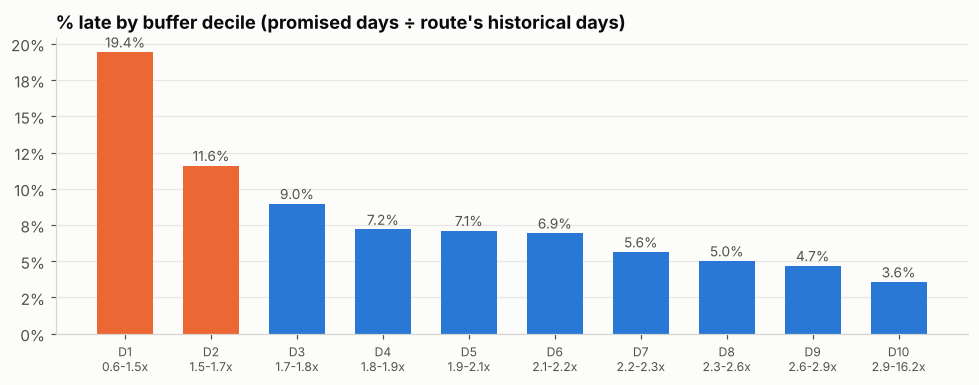

,late_pct,ratio_min,ratio_max
ratio_decile,,,
1,19.43,0.61,1.45
2,11.60,1.45,1.66
3,8.97,1.66,1.81
4,7.20,1.81,1.93
5,7.12,1.93,2.05
6,6.94,2.05,2.18
7,5.64,2.18,2.34
8,5.02,2.34,2.55
9,4.70,2.55,2.91


In [5]:
train = train.assign(ratio_decile=pd.qcut(train.promise_ratio, 10, labels=False) + 1)
by_decile = train.groupby("ratio_decile").agg(
    late_pct=("is_late", lambda s: 100 * s.mean()),
    ratio_min=("promise_ratio", "min"),
    ratio_max=("promise_ratio", "max"),
)

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [ORANGE if d <= 2 else BLUE for d in by_decile.index]
ax.bar(by_decile.index, by_decile.late_pct, color=colors, width=0.65)
for d, v in by_decile.late_pct.items():
    ax.annotate(f"{v:.1f}%", (d, v), textcoords="offset points", xytext=(0, 3),
                ha="center", fontsize=9, color=INK_2)
ax.set_xticks(by_decile.index)
ax.set_xticklabels([f"D{d}\n{r.ratio_min:.1f}-{r.ratio_max:.1f}x" for d, r in by_decile.iterrows()], fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("% late by buffer decile (promised days ÷ route's historical days)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_late_by_promise_ratio_decile.png", dpi=160)
by_decile.round(2)

The relationship is clear and monotonic:
- Short buffer (D1): when Olist promises less than ~1.45 times what the route took over the last 90 days, 19% of orders arrive late.
- Wide buffer (D7-D10): when it promises more than ~2.2 times, delays drop to between 3.6% and 5.6%.

In [6]:
X.to_csv("../data/processed/features.csv", index=False)
print("Features saved to data/processed/features.csv")

Features saved to data/processed/features.csv
